# EDA — Datos abiertos MiBici (Equipo 52)

Un registro por viaje. CSVs mensuales en `project_Data/Archivos MIBICI/` (dic-2014 a sep-2026, meses muestreados).

Imports y ruta a los datos.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm

plt.rcParams["figure.figsize"] = (12, 4)

DATA_DIR = Path("../project_Data/Archivos MIBICI")
files = sorted(DATA_DIR.glob("datos_abiertos_*.csv"))
print(len(files), "archivos")

72 archivos


## Carga
Los archivos vienen en 3 variantes (sin/comillas, UTF-8/Latin-1, y 3 headers corruptos `A}o`).
Esta función los lee tolerando todo eso. Tarda unos minutos: son ~19.7M viajes.
Para pruebas rápidas usar `files[:6]` o similar.

In [2]:
def leer_mibici(path):
    # detecta encoding por el header
    head = path.open("rb").read(4096)
    enc = "utf-8"
    try:
        head.decode("utf-8")
    except UnicodeDecodeError:
        enc = "latin-1"

    df = pd.read_csv(path, encoding=enc, na_values=["NULL"])
    df.columns = [
        "anio_de_nacimiento" if "nacimiento" in c.lower() else c.lower() for c in df.columns
    ]
    df["inicio_del_viaje"] = pd.to_datetime(df["inicio_del_viaje"], format="%Y-%m-%d %H:%M:%S")
    df["fin_del_viaje"] = pd.to_datetime(df["fin_del_viaje"], format="%Y-%m-%d %H:%M:%S")
    df["anio_de_nacimiento"] = pd.to_numeric(df["anio_de_nacimiento"], errors="coerce")
    df["periodo"] = re.search(r"(\d{4}_\d{2})", path.name).group(1)
    return df


viajes = pd.concat([leer_mibici(f) for f in tqdm(files)], ignore_index=True)
viajes["genero"] = viajes["genero"].astype("category")
viajes["periodo"] = viajes["periodo"].astype("category")
viajes.shape

100%|██████████| 72/72 [00:18<00:00,  3.81it/s]


(19725891, 9)

## Vista general
Primeras filas, tipos y % de nulos por columna.

In [3]:
display(viajes.head())
display(viajes.isna().mean().mul(100).round(2).rename("% nulos").to_frame())
print("viaje_id duplicados:", viajes["viaje_id"].duplicated().sum())

,viaje_id,usuario_id,genero,anio_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,periodo
0,4601,10324,M,NaN,2014-12-01 00:33:47,2014-12-01 00:36:54,47,47,2014_12
1,4604,10324,M,NaN,2014-12-01 01:06:54,2014-12-01 01:08:45,5,5,2014_12
2,4628,3,F,1990.0,2014-12-01 09:47:20,2014-12-01 09:47:47,79,79,2014_12
3,4631,102,M,1982.0,2014-12-01 09:48:23,2014-12-01 09:48:37,79,79,2014_12
4,4632,3,F,1990.0,2014-12-01 09:48:46,2014-12-01 09:48:57,79,79,2014_12


,% nulos
viaje_id,0.00
usuario_id,0.00
genero,0.38
anio_de_nacimiento,0.18
inicio_del_viaje,0.00
fin_del_viaje,0.00
origen_id,0.00
destino_id,0.00
periodo,0.00


viaje_id duplicados: 758


## Viajes por mes
Volumen mensual — ojo: solo meses con archivo, no es serie contigua.

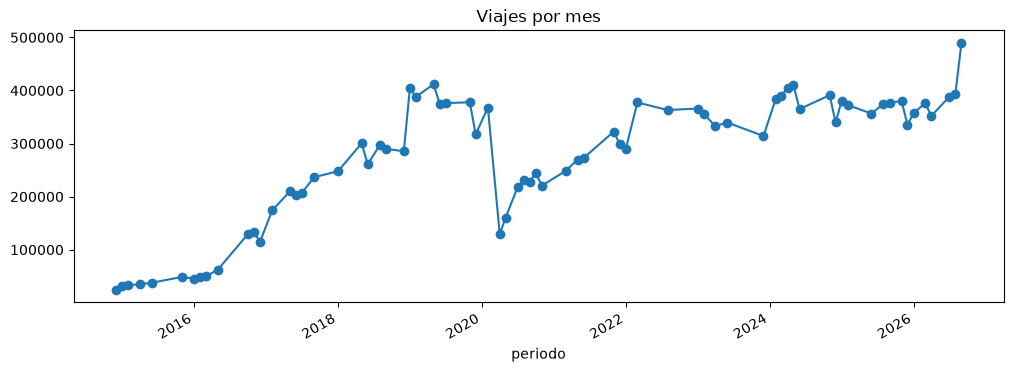

In [4]:
por_mes = viajes.groupby("periodo", observed=True).size()
por_mes.index = pd.to_datetime(por_mes.index.astype(str).str.replace("_", "-"))
por_mes.sort_index().plot(marker="o", title="Viajes por mes")
plt.show()

## Perfil horario y por día de la semana

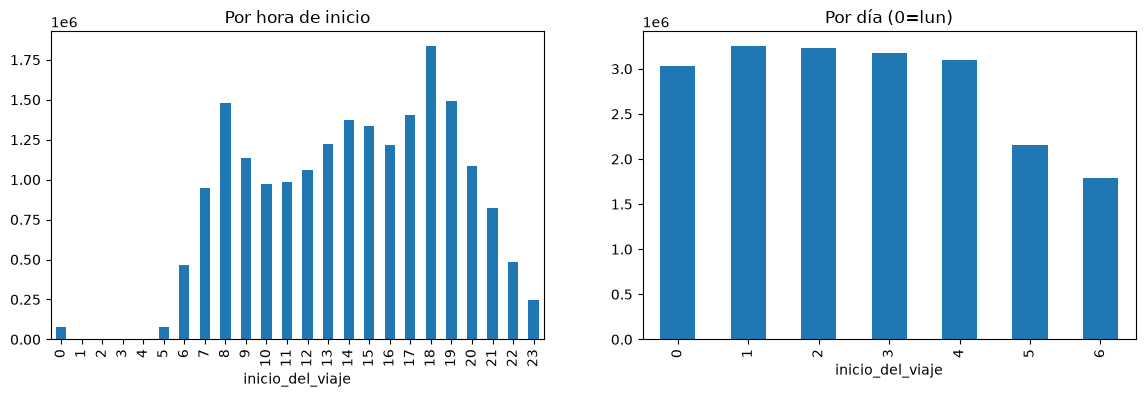

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
viajes["inicio_del_viaje"].dt.hour.value_counts().sort_index().plot(
    kind="bar", ax=axes[0], title="Por hora de inicio"
)
viajes["inicio_del_viaje"].dt.dayofweek.value_counts().sort_index().plot(
    kind="bar", ax=axes[1], title="Por día (0=lun)"
)
plt.show()

## Duración de viajes
Distribución y outliers (<=0 min, >1 h, >24 h).

count    1.972589e+07
mean     1.521140e+01
std      8.785390e+02
min      0.000000e+00
50%      9.416667e+00
90%      2.043333e+01
99%      3.313333e+01
max      5.264700e+05
Name: duracion_min, dtype: float64

<=0 min: 13680
>60 min: 27753
>24 h: 986


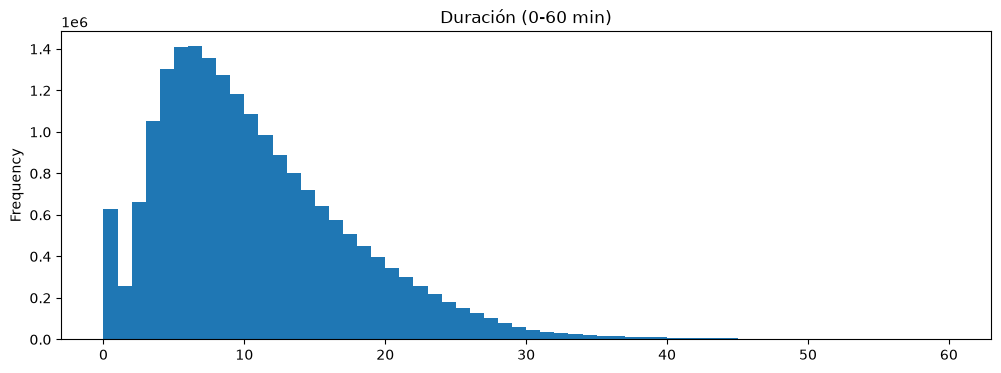

In [6]:
viajes["duracion_min"] = (
    viajes["fin_del_viaje"] - viajes["inicio_del_viaje"]
).dt.total_seconds() / 60

display(viajes["duracion_min"].describe(percentiles=[0.5, 0.9, 0.99]))
print("<=0 min:", (viajes["duracion_min"] <= 0).sum())
print(">60 min:", (viajes["duracion_min"] > 60).sum())
print(">24 h:", (viajes["duracion_min"] > 1440).sum())

viajes.loc[viajes["duracion_min"].between(0, 60), "duracion_min"].plot.hist(
    bins=60, title="Duración (0-60 min)"
)
plt.show()

## Usuarios
Cuántos viajes hace cada usuario.

usuarios únicos: 97879


count    97879.000000
mean       201.533434
std        403.438717
min          1.000000
50%         66.000000
90%        522.000000
99%       1952.440000
max      11500.000000
dtype: float64

con 1 solo viaje: 3.7%


,viajes
usuario_id,
51332,11500
501066,10270
253520,9656
47146,9420
106406,9079
434112,7964
324247,7731
20133,7393
105757,7253


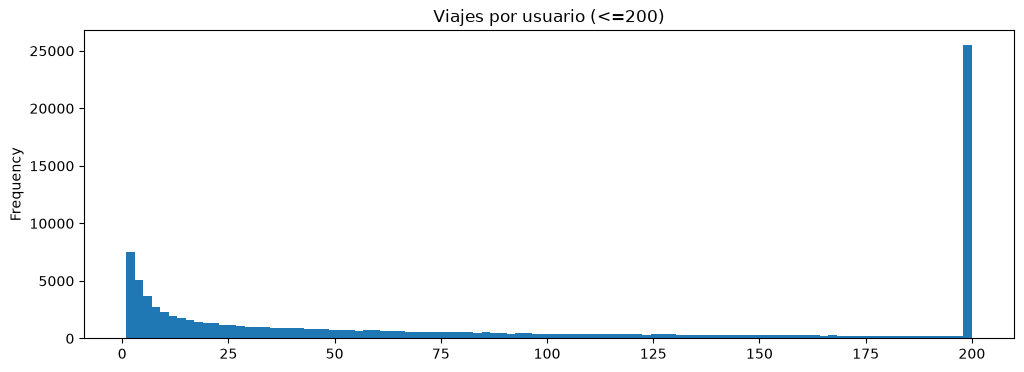

In [7]:
por_usuario = viajes.groupby("usuario_id").size()
print("usuarios únicos:", len(por_usuario))
display(por_usuario.describe(percentiles=[0.5, 0.9, 0.99]))
print("con 1 solo viaje: {:.1%}".format((por_usuario == 1).mean()))
display(por_usuario.nlargest(10).to_frame("viajes"))
por_usuario.clip(upper=200).plot.hist(bins=100, title="Viajes por usuario (<=200)")
plt.show()

## Género y edad

genero
M      14460667
F       5190284
NaN       74940
Name: count, dtype: int64

edades descartadas (NA o fuera de 10-100): 38881


count    1.968701e+07
mean     3.346185e+01
std      1.060157e+01
min      1.300000e+01
25%      2.600000e+01
50%      3.100000e+01
75%      3.900000e+01
max      1.000000e+02
dtype: float64

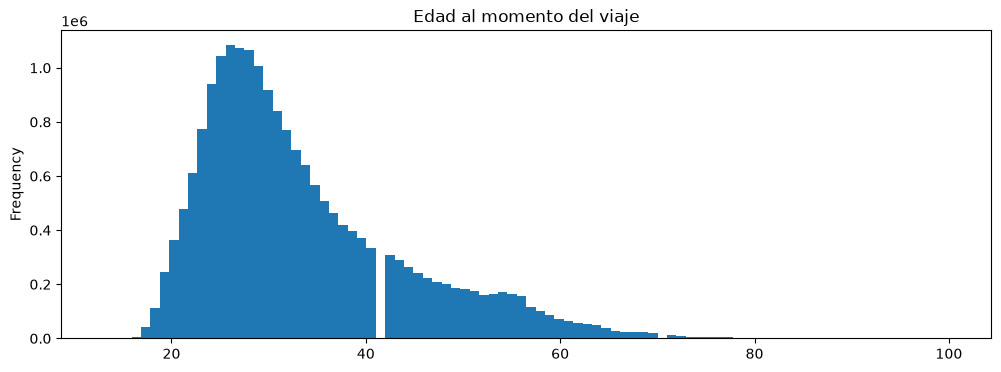

In [8]:
display(viajes["genero"].value_counts(dropna=False))

edad = viajes["inicio_del_viaje"].dt.year - viajes["anio_de_nacimiento"]
edad_ok = edad[edad.between(10, 100)]
print("edades descartadas (NA o fuera de 10-100):", len(edad) - len(edad_ok))
display(edad_ok.describe())
edad_ok.plot.hist(bins=90, title="Edad al momento del viaje")
plt.show()

## Estaciones
Top orígenes, % de viajes redondos y pares origen-destino más frecuentes.

estaciones origen: 485
estaciones destino: 485
redondos: 6.9%


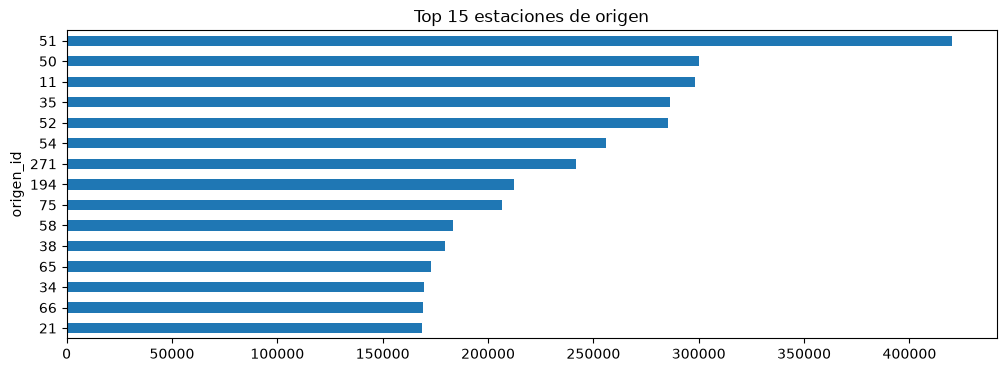

,,viajes
origen_id,destino_id,
51,51,24393
65,51,22247
50,50,20882
194,51,20208
66,51,20065
288,291,19086
51,65,18825
271,271,16780
75,75,16324


In [9]:
print("estaciones origen:", viajes["origen_id"].nunique())
print("estaciones destino:", viajes["destino_id"].nunique())
print("redondos: {:.1%}".format((viajes["origen_id"] == viajes["destino_id"]).mean()))

viajes["origen_id"].value_counts().head(15).sort_values().plot(
    kind="barh", title="Top 15 estaciones de origen"
)
plt.show()

display(
    viajes.groupby(["origen_id", "destino_id"]).size().nlargest(15).to_frame("viajes")
)